# 03 - Erro com pontos flutuantes
Vamos aprender sobre como usar os erros de ponto flutuante para resolução de problemas numéricos.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana3
```

Faça o checkout nessa nova branch:

```bash
git checkout semana3
```

<hr />

## Atividade 1
A função exponencial natural pode ser definida pelo limite:
$$
e^x=\lim_{n\to\infty}\left(1+\frac{x}{n}\right)^n,
$$
mas também é dada pela **série de Maclaurin**:
$$
e^x=\sum_{n=0}^{\infty}\frac{x^n}{n!}
=1+\frac{x}{1!}+\frac{x^2}{2!}+\frac{x^3}{3!}+\cdots
$$

Implemente em **Python** o cálculo de $e^x$ pela série, interrompendo a soma quando o termo ficar menor que o limite prático de contribuição, usando a precisão de máquina como critério.

In [2]:
import math
import sys

def exp_series(x, atol=0.0):
    """ Aproxima e^x pela série de Maclaurin com critério de parada numérico. """
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    tol_abs = max(atol, eps)

    while True:
        n += 1
        term *= x / n
        s += term
        if abs(term) < eps * abs(s) or abs(term) < tol_abs:
            break
        if n > 10_000:
            break
    return s, n, term

# Demonstração
for val in [1.0, 5.0, -2.0]:
    approx, nterms, last = exp_series(val)
    print(f"x={val:+g} -> e^x ≈ {approx:.16g} (math.exp={math.exp(val):.16g}, termos={nterms})")

x=+1 -> e^x ≈ 2.718281828459046 (math.exp=2.718281828459045, termos=18)
x=+5 -> e^x ≈ 148.4131591025766 (math.exp=148.4131591025766, termos=33)
x=-2 -> e^x ≈ 0.1353352832366127 (math.exp=0.1353352832366127, termos=24)


## Atividade 2

Implemente:
$$
e^x\approx\left(1+\frac{x}{n}\right)^n
$$
com $n$ crescente, e:
1. Explique por que, para $x<0$ e $n$ muito grande, pode ocorrer **cancelamento catastrófico**;
2. Proponha um critério de parada numérico para encerrar o crescimento de $n$ sem perder precisão.

## 1.
Quando $x < 0$, a expressão $1 + \frac{x}{n}$ equivale a subtrair um número de $1$. À medida que $n$ se torna extremamente grande, o valor absoluto de $\frac{x}{n}$ torna-se minúsculo.Devido à limitação de 64 bits do ponto flutuante (cujo limite de resolução é o machine epsilon, tipicamente em torno de $2.22 \times 10^{-16}$), ocorre o fenômeno de absorção (onde números de magnitudes muito diferentes são somados/subtraídos e a precisão do menor é descartada).Se $n$ crescer tanto que $\left\vert{}\frac{x}{n}\right\vert{} < \epsilon$, a máquina calculará a expressão $1 + \frac{x}{n}$ como exatamente $1.0$. Consequentemente, a operação final será $1.0^n = 1$, destruindo completamente a aproximação do verdadeiro valor de $e^x$.

Como a convergência do limite $\lim_{n \to \infty} \left(1 + \frac{x}{n}\right)^n$ é extremamente lenta, incrementar $n$ de 1 em 1 não é prático. É ideal usar um crescimento geométrico (ex: $n = 2, 4, 8, 16 \dots$).O critério de parada não pode observar "um termo" sendo somado (como na série de Maclaurin), mas sim a diferença entre as aproximações sucessivas. O algoritmo deve parar o crescimento de $n$ quando:A diferença entre o resultado atual e o anterior for menor que a resolução da máquina ($\epsilon$).A diferença entre o resultado atual e o anterior parar de diminuir ou começar a aumentar (o que indica que os erros de arredondamento de ponto flutuante começaram a dominar sobre a precisão matemática ganha pelo aumento de $n$).

In [1]:
import math
import sys

def exp_limite(x):
    """ Aproxima e^x usando (1 + x/n)^n com n crescente e parada automática. """
    eps = sys.float_info.epsilon
    n = 1
    
    # Primeira aproximação
    prev_approx = (1 + x / n) ** n
    n *= 2
    prev_diff = float('inf')
    
    while True:
        # Calcula a aproximação atual
        approx = (1 + x / n) ** n
        
        # Verifica o tamanho do salto/diferença entre iterações
        diff = abs(approx - prev_approx)
        
        # Critério de parada:
        # 1. diff <= eps * abs(approx): atingiu o limite de tolerância relativa
        # 2. diff >= prev_diff: o erro começou a aumentar (falta de precisão de float)
        if diff <= eps * abs(approx) or diff >= prev_diff:
            return prev_approx, n // 2  # Retorna a melhor aproximação (anterior à piora)
        
        # Prepara para a próxima iteração com crescimento geométrico de n
        prev_approx = approx
        prev_diff = diff
        n *= 2

# Demonstração
for val in [1.0, 5.0, -2.0, -10.0]:
    approx, n_final = exp_limite(val)
    print(f"x={val:+g} -> e^x ≈ {approx:.10g} (math.exp={math.exp(val):.10g}, n={n_final})")

x=+1 -> e^x ≈ 2.718281828 (math.exp=2.718281828, n=1125899906842624)
x=+5 -> e^x ≈ 12.25 (math.exp=148.4131591, n=2)
x=-2 -> e^x ≈ 0.1353352832 (math.exp=0.1353352832, n=4503599627370496)
x=-10 -> e^x ≈ 6.204781322e-06 (math.exp=4.539992976e-05, n=32)


## Atividade 3

Para $|x|$ grande, use:
$$
e^x = \left(e^{m\cdot 2^{-k}}\right)^{2^k}, \quad
k = \left\lceil \log_2\!\left(\frac{|x|}{\theta}\right)\right\rceil, \quad m = \frac{x}{2^k}
$$
Calcule $e^{m}$ pela série (Ex. 1) e depois eleve ao quadrado $k$ vezes.

In [3]:
import math
import sys

def exp_series(x, atol=0.0):
    """ Aproxima e^x pela série de Maclaurin (Código base do Ex. 1). """
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    tol_abs = max(atol, eps)

    while True:
        n += 1
        term *= x / n
        s += term
        if abs(term) < eps * abs(s) or abs(term) < tol_abs:
            break
        if n > 10_000:
            break
    return s

def exp_scale_and_square(x, theta=1.0):
    """
    Calcula e^x usando a técnica de 'scaling and squaring'.
    theta: limiar para |x|. Valores típicos são 0.5 ou 1.0.
    """
    # 1. Determinar o número de reduções (k)
    if abs(x) <= theta:
        k = 0
    else:
        k = int(math.ceil(math.log2(abs(x) / theta)))
        
    # 2. Calcular m (o valor reduzido)
    m = x / (2**k)
    
    # 3. Calcular e^m pela série de Maclaurin
    exp_m = exp_series(m)
    
    # 4. Elevar ao quadrado k vezes
    result = exp_m
    for _ in range(k):
        result *= result
        
    return result, k, m

# Demonstração para valores grandes de |x|
for val in [5.0, -10.0, 25.0, -30.0]:
    approx, k_utilizado, m_reduzido = exp_scale_and_square(val)
    # Comparação com o math.exp real
    try:
        real_val = math.exp(val)
    except OverflowError:
        real_val = float('inf')
        
    print(f"x={val:+5g} | k={k_utilizado:2d} | m={m_reduzido:+.4f} | e^x ≈ {approx:.10g} (math.exp={real_val:.10g})")

x=   +5 | k= 3 | m=+0.6250 | e^x ≈ 148.4131591 (math.exp=148.4131591)
x=  -10 | k= 4 | m=-0.6250 | e^x ≈ 4.539992976e-05 (math.exp=4.539992976e-05)
x=  +25 | k= 5 | m=+0.7812 | e^x ≈ 7.200489934e+10 (math.exp=7.200489934e+10)
x=  -30 | k= 5 | m=-0.9375 | e^x ≈ 9.357622969e-14 (math.exp=9.357622969e-14)


## Atividade 4

Use:
$$
\cos x=\sum_{n=0}^{\infty}(-1)^n\frac{x^{2n}}{(2n)!}
$$
com a recursão:
$$
t_{n+1}=t_n\cdot\frac{-x^2}{(2n+1)(2n+2)}
$$
Defina um critério de parada baseado em `epsilon` e compare o erro relativo para $x\in[-20,20]$ (200 pontos) contra `math.cos(x)`.

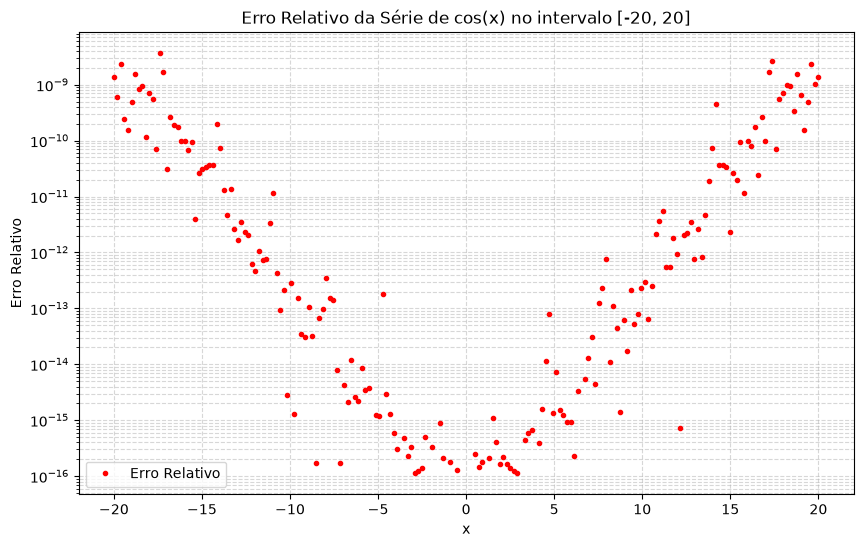

In [4]:
import math
import sys
import numpy as np
import matplotlib.pyplot as plt

def cos_series(x, atol=0.0):
    """
    Aproxima cos(x) pela série de Maclaurin utilizando a recursão dada.
    """
    eps = sys.float_info.epsilon
    term = 1.0  # Para n=0, o termo é x^0 / 0! = 1
    s = 1.0     # A soma inicializa com o primeiro termo
    n = 0
    tol_abs = max(atol, eps)

    while True:
        # Aplicação da recursão fornecida no enunciado
        term *= - (x**2) / ((2*n + 1) * (2*n + 2))
        s += term
        n += 1
        
        # Critério de paragem: o termo atual é insignificante face à soma
        if abs(term) < eps * abs(s) or abs(term) < tol_abs:
            break
        
        # Limite de segurança para evitar loops infinitos
        if n > 10_000:
            break
            
    return s, n

# 1. Gerar 200 pontos no intervalo [-20, 20]
x_vals = np.linspace(-20, 20, 200)
erros_relativos = []

# 2. Calcular a série e o erro relativo para cada ponto
for x in x_vals:
    approx, iteracoes = cos_series(x)
    real = math.cos(x)
    
    # Cálculo do erro relativo: |(valor_aproximado - valor_real) / valor_real|
    # Adicionamos uma pequena constante no denominador para evitar divisão por zero
    # caso math.cos(x) seja exatamente 0 (ou muito próximo)
    if real == 0:
        erro = abs(approx - real)
    else:
        erro = abs((approx - real) / real)
        
    erros_relativos.append(erro)

# 3. Visualizar os resultados
plt.figure(figsize=(10, 6))
plt.plot(x_vals, erros_relativos, marker='.', linestyle='none', color='red', label='Erro Relativo')
plt.yscale('log') # Escala logarítmica para ver as variações do erro
plt.title('Erro Relativo da Série de cos(x) no intervalo [-20, 20]')
plt.xlabel('x')
plt.ylabel('Erro Relativo')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

## Atividade 5

Dado $x$ e uma tolerância $\tau$, encontre o menor $N$ tal que:
$$
R_{N+1}(x)=\sum_{n=N+1}^{\infty}\frac{|x|^n}{n!} < \tau
$$

In [5]:
import math

def encontrar_n_minimo(x, tau):
    """
    Encontra o menor N tal que o resto da série para e^|x| seja menor que a tolerância tau.
    """
    abs_x = abs(x)
    valor_exato = math.exp(abs_x)
    
    n = 0
    termo = 1.0       # Termo inicial para n=0: |x|^0 / 0! = 1
    soma_parcial = 1.0 # Soma inicial contendo apenas o termo n=0
    
    while True:
        # O resto é a diferença entre o valor real e a aproximação atual
        resto = valor_exato - soma_parcial
        
        # Critério de paragem
        if resto < tau:
            return n, resto
            
        # Avançar para o próximo N
        n += 1
        
        # Calcular o próximo termo usando a relação de recorrência: t_n = t_{n-1} * (|x| / n)
        termo *= abs_x / n
        soma_parcial += termo

# Demonstração
x_teste = 5.0
tolerancias = [1e-3, 1e-6, 1e-9]

for tau_teste in tolerancias:
    n_min, resto_final = encontrar_n_minimo(x_teste, tau_teste)
    print(f"Para x={x_teste} e \u03c4={tau_teste}: N={n_min} (Resto alcançado: {resto_final:.2e})")

Para x=5.0 e τ=0.001: N=17 (Resto alcançado: 8.04e-04)
Para x=5.0 e τ=1e-06: N=22 (Resto alcançado: 5.81e-07)
Para x=5.0 e τ=1e-09: N=26 (Resto alcançado: 8.32e-10)


## Atividade 6

Usando `decimal` ou `mpmath`, compute $e^x$ em alta precisão e compare com o resultado de `float64` (Ex. 1) para $x\in\{20, 40, 50\}$.
Analise:
- perda de dígitos significativos;
- quando o `float64` começa a saturar por overflow.


In [6]:
import sys
from decimal import Decimal, getcontext

# Configurar o contexto do decimal para alta precisão (ex: 50 dígitos)
getcontext().prec = 50

def exp_series_float64(x):
    """ Aproxima e^x pela série de Maclaurin usando float64 (Código Ex. 1). """
    eps = sys.float_info.epsilon
    s = 1.0
    term = 1.0
    n = 0
    
    while True:
        n += 1
        # Usando float normal (64-bits)
        term *= float(x) / n
        s += term
        if abs(term) < eps * abs(s):
            break
        if n > 10_000:
            break
    return s

# Valores a testar definidos na Atividade 6
valores_x = [20, 40, 50]

for x_val in valores_x:
    # 1. Cálculo em Alta Precisão (Decimal)
    x_dec = Decimal(x_val)
    exp_alta_precisao = x_dec.exp()
    
    # 2. Cálculo em Float64
    try:
        exp_float64 = exp_series_float64(x_val)
        # Cálculo do erro relativo convertido para float para facilitar a leitura
        erro_relativo = abs(float(exp_alta_precisao) - exp_float64) / float(exp_alta_precisao)
    except OverflowError:
        exp_float64 = "Overflow"
        erro_relativo = "N/A"
        
    print(f"--- Para x = {x_val} ---")
    print(f"Decimal (Alta) : {exp_alta_precisao}")
    print(f"Float64 (Ex 1) : {exp_float64}")
    print(f"Erro Relativo  : {erro_relativo:.5e}\n")

--- Para x = 20 ---
Decimal (Alta) : 485165195.40979027796910683054154055868463898894485
Float64 (Ex 1) : 485165195.40979046
Erro Relativo  : 3.68563e-16

--- Para x = 40 ---
Decimal (Alta) : 235385266837019985.40789991074903480450887161725456
Float64 (Ex 1) : 2.3538526683702006e+17
Erro Relativo  : 2.71895e-16

--- Para x = 50 ---
Decimal (Alta) : 5184705528587072464087.4533229334853848274691005838
Float64 (Ex 1) : 5.184705528587081e+21
Erro Relativo  : 1.82020e-15



## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 3"
git push origin semana3
```